In [ ]:
import astropy.units as u
import numpy as np
from snewpy.flavor_transformation import EarthMatter
from snewpy.neutrino import MixingParameters, MassHierarchy
from astropy.coordinates import AltAz
from tqdm.auto import tqdm, trange

matrices = {}
energy = np.linspace(1,100,800)<<u.MeV
time = np.linspace(0,2,800)<<u.s
for angle in trange(-90, 1, 1):
    for mh in MassHierarchy:
        altaz_nh = AltAz(alt=angle*u.deg, az=0*u.deg)
        flavor_transform = EarthMatter(AltAz=altaz_nh, mixing_params= MixingParameters(mh))
        M = flavor_transform.P_ff(time, energy)
        matrices[f'M_{angle:d}_{mh.name}'] = M.array

np.savez('flavor_matrix.npz', 
         **matrices,
         T=time.to_value('s'), 
         E=energy.to_value('MeV'))

## Reading matrices

In [30]:
from snewpy.flavor import FlavorMatrix, ThreeFlavor
from snewpy.models import ccsn

m_file = np.load('flavor_matrix.npz')
M1 = FlavorMatrix(array=m_file['M_-90_INVERTED'], flavor=ThreeFlavor)
time = m_file['T'] <<u.s
energy = m_file['E'] <<u.MeV

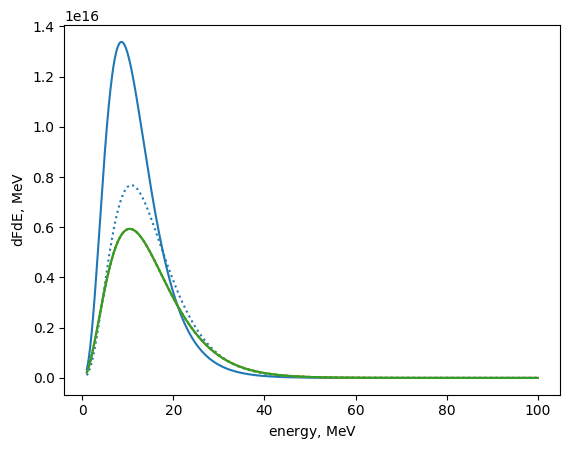

[[<matplotlib.lines.Line2D at 0x7f255f610100>],

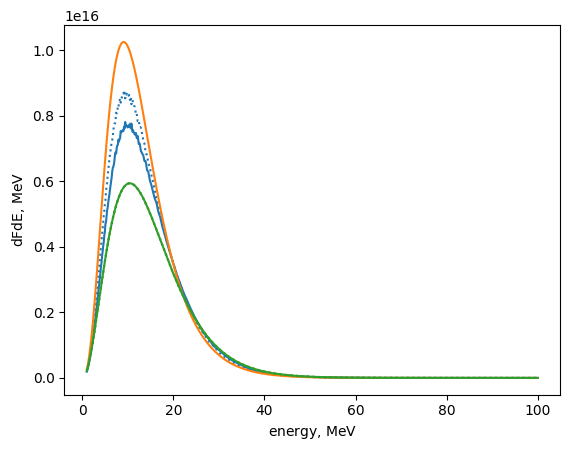

In [33]:
model = ccsn.Bollig_2016(progenitor_mass=27<<u.Msun)
flux = model.get_flux(time, energy, distance=1*u.kpc)
flux.plot()
plt.show()
(M1@flux).plot()

In [38]:
class MatrixLoader:
    def __init__(self, filepath='flavor_matrix.npz'):
        self.filepath = filepath
        self.data = None
        self.time = None
        self.energy = None
        self._load_data()

    def _load_data(self):
        self.data = np.load(self.filepath)
        self.time = self.data['T'] << u.s
        self.energy = self.data['E'] << u.MeV

    def get_matrix(self, angle, hierarchy):
        array = self.data[f'M_{angle}_{hierarchy}']
        return FlavorMatrix(array=array, flavor=ThreeFlavor), self.time,  self.energy
        
    def apply_to_flux(self, matrix, model, distance=10):
        M = matrix
        flux = model.get_flux(self.time, self.energy, distance=distance*u.kpc)
        transformed_flux = (M @ flux)
        return transformed_flux
    